# LAB 01 — From Text Processing to Search (experiments)

**Corpus:** 30 000 abstract bài báo Machine Learning trên arXiv (`CShorten/ML-ArXiv-Papers`, lấy mẫu ngẫu nhiên seed 42 sau khi bỏ trùng tiêu đề). Mỗi document = `title + ". " + abstract`.

Thứ tự: B (kiểm chứng tính tay) → D (sparse representation) → E (implementation vs thư viện) → F (preprocessing ablation) → G (search) → H (evaluation) → I (error analysis).

In [1]:
import os, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"; os.environ["HF_HUB_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")
import json, math, re, time, unicodedata
import numpy as np, pandas as pd, scipy.sparse as sp
import matplotlib.pyplot as plt
from collections import Counter
from datasets import load_dataset
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
import implementation as impl

pd.set_option("display.max_colwidth", 90)
SEED = 42

raw = load_dataset("CShorten/ML-ArXiv-Papers", split="train").to_pandas()[["title", "abstract"]].dropna()
for c in ["title", "abstract"]:
    raw[c] = raw[c].str.replace(r"\s+", " ", regex=True).str.strip()
raw = raw.drop_duplicates("title")
df = raw.sample(n=30000, random_state=SEED).reset_index(drop=True)
df["doc_id"] = [f"D{i:05d}" for i in range(len(df))]
df["text"] = df.title + ". " + df.abstract
docs = df.text.tolist()
print(f"Dataset gốc sau khi bỏ trùng: {len(raw)} | Corpus dùng: {len(df)} documents")
print("Số từ / document:", df.text.str.split().str.len().describe().round(1).to_dict())
df[["doc_id", "title"]].head(3)

Dataset gốc sau khi bỏ trùng: 113277 | Corpus dùng: 30000 documents


Số từ / document: {'count': 30000.0, 'mean': 175.8, 'std': 50.6, 'min': 10.0, '25%': 140.0, '50%': 173.0, '75%': 209.0, 'max': 330.0}


,doc_id,title
0,D00000,Artificial Neural Networks for Sensor Data Classification on Small Embedded Systems
1,D00001,The Second International Verification of Neural Networks Competition (VNN-COMP 2021): ...
2,D00002,An Accelerated Variance-Reduced Conditional Gradient Sliding Algorithm for First-order...


## Part B — Kiểm chứng bài tính tay (`calculations.md`)
Dùng `implementation.py` (tự cài đặt), log tự nhiên.

In [2]:
C3 = ["cat eats fish", "dog eats fish", "cat likes fish"]
V3 = impl.build_vocabulary(C3)
cnt = impl.compute_counts(C3, V3); tf = impl.compute_tf(cnt); idf = impl.compute_idf(cnt)
X3 = impl.compute_tfidf(tf, idf)
print("Ex1 vocabulary:", V3)
print(pd.DataFrame(cnt.astype(int), index=["D1", "D2", "D3"], columns=V3))
print("\nEx2 TF(D1):", dict(zip(V3, tf[0].round(4))), "| tổng =", tf[0].sum())
print("Ex3 IDF:", dict(zip(V3, idf.round(4))))
print("Ex4 TF-IDF(D1):", dict(zip(V3, X3[0].round(4))))
print("Ex5 cos([1,1,1],[1,1,0]) =", round(impl.cosine_similarity([1, 1, 1], [1, 1, 0]), 4), "| 2/3 =", round(2 / 3, 4))

C6 = ["medical image classification", "medical image analysis", "natural language processing"]
V6 = impl.build_vocabulary(C6 + ["medical image classification"])
cnt6 = impl.compute_counts(C6, V6); idf6 = impl.compute_idf(cnt6)
q_cnt = impl.compute_counts(["medical image classification"], V6)
q_tfidf = impl.compute_tfidf(impl.compute_tf(q_cnt), idf6)[0]
D_tfidf = impl.compute_tfidf(impl.compute_tf(cnt6), idf6)
print("\nEx6 IDF:", dict(zip(V6, idf6.round(3))))
print(pd.DataFrame({"cos TF-IDF": [impl.cosine_similarity(q_tfidf, d) for d in D_tfidf],
                    "cos count": [impl.cosine_similarity(q_cnt[0], d) for d in cnt6]},
                   index=["D1", "D2", "D3"]).round(4))

Ex1 vocabulary: ['cat', 'dog', 'eats', 'fish', 'likes']
    cat  dog  eats  fish  likes
D1    1    0     1     1      0
D2    0    1     1     1      0
D3    1    0     0     1      1

Ex2 TF(D1): {'cat': np.float64(0.3333), 'dog': np.float64(0.0), 'eats': np.float64(0.3333), 'fish': np.float64(0.3333), 'likes': np.float64(0.0)} | tổng = 1.0
Ex3 IDF: {'cat': np.float64(0.4055), 'dog': np.float64(1.0986), 'eats': np.float64(0.4055), 'fish': np.float64(0.0), 'likes': np.float64(1.0986)}
Ex4 TF-IDF(D1): {'cat': np.float64(0.1352), 'dog': np.float64(0.0), 'eats': np.float64(0.1352), 'fish': np.float64(0.0), 'likes': np.float64(0.0)}
Ex5 cos([1,1,1],[1,1,0]) = 0.8165 | 2/3 = 0.6667

Ex6 IDF: {'analysis': np.float64(1.099), 'classification': np.float64(1.099), 'image': np.float64(0.405), 'language': np.float64(1.099), 'medical': np.float64(0.405), 'natural': np.float64(1.099), 'processing': np.float64(1.099)}
    cos TF-IDF  cos count
D1      1.0000     1.0000
D2      0.2141     0.6667
D3   

## Part D — Experiment 1: Sparse representation trên 30K documents
Pipeline: `raw → tokenizer (CountVectorizer) → counts → TF = c/Σc → IDF = ln(N/df) → TF-IDF`. TF và IDF được tính bằng công thức tự viết trên ma trận sparse (CountVectorizer chỉ dùng để tokenize + đếm).

In [3]:
cv = CountVectorizer(lowercase=True)            # token_pattern mặc định: \b\w\w+\b
t0 = time.time()
Cnt = cv.fit_transform(docs).astype(np.float64)  # N x V, CSR
vocab = cv.get_feature_names_out()
N, V = Cnt.shape
doc_len = np.asarray(Cnt.sum(axis=1)).ravel()
TF = sp.diags(1 / doc_len) @ Cnt                                  # tf = c / Σc
DF = np.asarray((Cnt > 0).sum(axis=0)).ravel()
IDF = np.log(N / DF)
X = (TF @ sp.diags(IDF)).tocsr()                                  # tf-idf
print(f"Thời gian: {time.time() - t0:.1f}s")
nnz = X.nnz
print(f"Number of documents N = {N}\nVocabulary size     V = {V}\nMatrix shape          = {X.shape}")
print(f"nnz(X) = {nnz:,} | sparsity S = 1 - nnz/(N*V) = {1 - nnz / (N * V):.6f} ({100 * (1 - nnz / (N * V)):.3f}% zeros)")
print(f"Số term khác 0 trung bình / document = {nnz / N:.1f} ({100 * nnz / N / V:.3f}% của V)")
print(f"Bộ nhớ dense float64 sẽ cần {N * V * 8 / 1e9:.1f} GB; CSR thực tế ≈ {(X.data.nbytes + X.indices.nbytes + X.indptr.nbytes) / 1e6:.1f} MB")

Thời gian: 3.1s
Number of documents N = 30000
Vocabulary size     V = 54335
Matrix shape          = (30000, 54335)
nnz(X) = 3,204,749 | sparsity S = 1 - nnz/(N*V) = 0.998034 (99.803% zeros)
Số term khác 0 trung bình / document = 106.8 (0.197% của V)
Bộ nhớ dense float64 sẽ cần 13.0 GB; CSR thực tế ≈ 38.6 MB


In [4]:
top_df = pd.DataFrame({"term": vocab, "df": DF, "idf": IDF}).sort_values("df", ascending=False).head(20).reset_index(drop=True)
top_idf = pd.DataFrame({"term": vocab, "df": DF, "idf": IDF}).sort_values(["idf", "term"], ascending=[False, True]).head(20).reset_index(drop=True)
doc_sel = df.index[df.doc_id == "D12572"][0]          # "HMIC: Hierarchical Medical Image Classification..."
row = X[doc_sel].toarray().ravel(); cnt_row = Cnt[doc_sel].toarray().ravel()
o = np.argsort(-row)[:20]
top_doc = pd.DataFrame({"term": vocab[o], "count": cnt_row[o].astype(int), "df": DF[o], "tfidf": row[o].round(4)})
print("Document được chọn:", df.doc_id[doc_sel], "-", df.title[doc_sel])
pd.concat({"Top-20 DF": top_df, "Top-20 IDF": top_idf, "Top-20 TF-IDF trong D12572": top_doc}, axis=1)

Document được chọn: D12572 - HMIC: Hierarchical Medical Image Classification, A Deep Learning Approach


Top-20 DF                  Top-20 IDF                \
        term     df       idf       term df        idf   
0        the  29879  0.004041      00000  1  10.308953   
1         of  29698  0.010118    0000001  1  10.308953   
2        and  29383  0.020781      0000_  1  10.308953   
3         to  29099  0.030494     000205  1  10.308953   
4         in  28523  0.050487       0003  1  10.308953   
5         we  27108  0.101368       0007  1  10.308953   
6        for  26390  0.128212      00075  1  10.308953   
7       that  24565  0.199875       0008  1  10.308953   
8         is  24468  0.203831      0008s  1  10.308953   
9       this  24308  0.210392       000s  1  10.308953   
10        on  23690  0.236144       0018  1  10.308953   
11      with  22295  0.296835      00194  1  10.308953   
12  learning  18201  0.499721       001s  1  10.308953   
13        by  17948  0.513719     002735  1  10.308953   
14        as  17579  0.534492       0028  1  10.308953   
15       are  17559  0.535631       0032  1  10.308953   
16        an  17195  0.556579       0033  1  10.308953   
17       our  15733  0.645437      00335  1  10.308953   
18       can  14862  0.702390       0040  1  10.308953   
19      from  14850  0.703198       0041  1  10.308953   

   Top-20 TF-IDF trong D12572                      
                         term count    df   tfidf  
0                        hmic     3     1  0.2035  
1                      celiac     2     1  0.1356  
2                     medical     4   801  0.0953  
3              classification     7  5074  0.0818  
4                hierarchical     3   786  0.0719  
5                 enteropathy     1     1  0.0678  
6                        iiic     1     1  0.0678  
7                        iiia     1     1  0.0678  
8                        iiib     1     1  0.0678  
9              histologically     1     2  0.0633  
10                      bowel     1     4  0.0587  
11                      image     4  3379  0.0575  
12                    disease     2   481  0.0544  
13                     biopsy     1    17  0.0492  
14                      level     3  2510  0.0490  
15                   outlines     1    21  0.0478  
16                     stacks     1    29  0.0457  
17                     parent     1    35  0.0444  
18                      child     1    36  0.0442  
19                 revolution     1    42  0.0432

Số term có df = 1 (hapax theo document): 28120 (51.8% vocabulary) -> tất cả cùng IDF max = ln(N) = 10.309
df của 3 term top-DF: {'the': 29879, 'of': 29698, 'and': 29383} → IDF ≈ [0.004, 0.01, 0.021]
Tỉ lệ term top-20 DF xuất hiện trong top-20 TF-IDF của D12572: 0 / 20


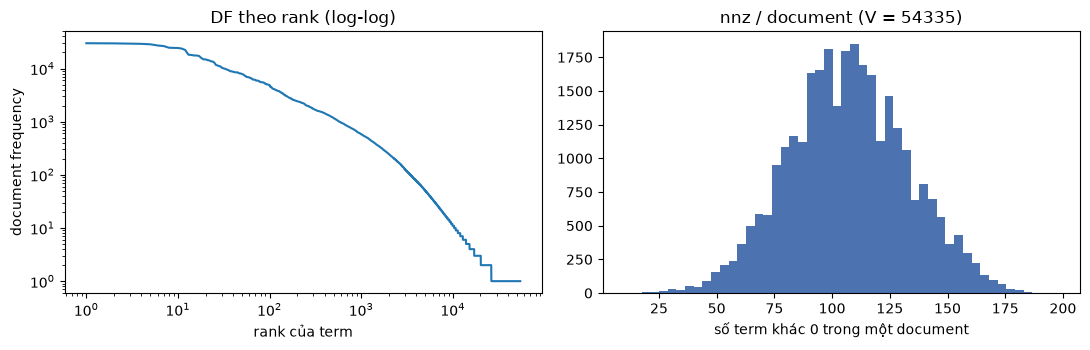

In [5]:
print(f"Số term có df = 1 (hapax theo document): {(DF == 1).sum()} ({100 * (DF == 1).mean():.1f}% vocabulary) -> tất cả cùng IDF max = ln(N) = {math.log(N):.3f}")
print("df của 3 term top-DF:", dict(zip(top_df.term[:3], top_df.df[:3])), "→ IDF ≈", top_df.idf[:3].round(3).tolist())
print("Tỉ lệ term top-20 DF xuất hiện trong top-20 TF-IDF của D12572:", len(set(top_df.term) & set(top_doc.term)), "/ 20")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].loglog(np.arange(1, V + 1), np.sort(DF)[::-1]); ax[0].set_xlabel("rank của term"); ax[0].set_ylabel("document frequency"); ax[0].set_title("DF theo rank (log-log)")
ax[1].hist(np.diff(X.indptr), bins=50, color="#4c72b0"); ax[1].set_xlabel("số term khác 0 trong một document"); ax[1].set_title(f"nnz / document (V = {V})")
plt.tight_layout(); plt.savefig("sparsity.png", dpi=150); plt.show()

## Part E — Student implementation vs reference implementation
1. Chạy unit tests của `implementation.py`.
2. So với `TfidfVectorizer` trên corpus kiểm thử: khác nhau ở **convention**, không phải bug.

In [6]:
impl.run_tests()

PASS  test_build_vocabulary
PASS  test_compute_counts
PASS  test_compute_tf
PASS  test_compute_idf
PASS  test_compute_tfidf
PASS  test_cosine_similarity
6/6 tests passed


In [7]:
sk = TfidfVectorizer()                                 # mặc định: raw count, smooth_idf=True, norm='l2'
Xsk = sk.fit_transform(C3).toarray()
assert list(sk.get_feature_names_out()) == V3          # cùng vocabulary ordering (alphabet)
mine_plain = impl.compute_tfidf(tf, impl.compute_idf(cnt))                                  # tf=c/Σc, idf=ln(N/df)
mine_match = impl.compute_tfidf(cnt, impl.compute_idf(cnt, smooth=True), normalize=True)    # raw count, smooth idf, L2
print("sklearn idf_:", sk.idf_.round(4), "\nmine smooth:", impl.compute_idf(cnt, smooth=True).round(4))
print(pd.DataFrame({"sklearn": Xsk[0], "mine (lecture)": mine_plain[0], "mine (sklearn conv.)": mine_match[0]}, index=V3).round(4))
print("max |diff| khi cùng convention:", np.abs(Xsk - mine_match).max())
# cosine không đổi khi nhân mỗi vector với hằng số → TF = c/Σc và raw count cho cùng cosine nếu cùng IDF
A = impl.compute_tfidf(tf, impl.compute_idf(cnt, smooth=True)); B = impl.compute_tfidf(cnt, impl.compute_idf(cnt, smooth=True))
print("cos(D1,D3) với tf=c/Σc:", round(impl.cosine_similarity(A[0], A[2]), 6), "| với raw count:", round(impl.cosine_similarity(B[0], B[2]), 6))

sklearn idf_: [1.2877 1.6931 1.2877 1.     1.6931] 
mine smooth: [1.2877 1.6931 1.2877 1.     1.6931]
       sklearn  mine (lecture)  mine (sklearn conv.)
cat     0.6198          0.1352                0.6198
dog     0.0000          0.0000                0.0000
eats    0.6198          0.1352                0.6198
fish    0.4813          0.0000                0.4813
likes   0.0000          0.0000                0.0000
max |diff| khi cùng convention: 0.0
cos(D1,D3) với tf=c/Σc: 0.544328 | với raw count: 0.544328


In [8]:
# Kiểm chứng ở quy mô lớn: pipeline sparse (Part D, công thức tự viết) vs TfidfVectorizer cùng convention
sk30 = TfidfVectorizer(smooth_idf=False, norm=None, sublinear_tf=False)
Xsk30 = sk30.fit_transform(docs)
# sklearn smooth_idf=False dùng ln(N/df) + 1 và raw count; đưa về công thức lecture: (X_sk - Cnt) / doc_len
mine_from_sk = sp.diags(1 / doc_len) @ (Xsk30 - Cnt)
print("Cùng vocabulary:", (sk30.get_feature_names_out() == vocab).all(),
      "| max |diff| =", abs(mine_from_sk - X).max())

Cùng vocabulary: True | max |diff| = 2.220446049250313e-16


## Part F — Experiment 2: Preprocessing ablation

| Pipeline | Các bước |
|---|---|
| **A — Minimal** | lowercase → tách theo khoảng trắng (dấu câu dính vào từ: `model,` ≠ `model`) |
| **B — Normalized** | lowercase → NFKC + thay mọi ký tự không phải chữ/số bằng khoảng trắng → tokenize → bỏ stopwords (318 stopwords của scikit-learn) |
| **C — Extended** | normalization như B (không bỏ stopwords) → subword tokenization WordPiece (`bert-base-uncased`, vocab 30 522) |

Hai biến thể phụ để trả lời câu hỏi phân tích: **A0** (A nhưng *không* lowercase) và **B−sw** (B nhưng *giữ* stopwords).

Mọi pipeline dùng cùng weighting: `TfidfVectorizer` (raw tf × smooth idf, L2-norm) với tokenizer tương ứng, cosine = tích vô hướng.
**OOV rate:** fit vocabulary trên 27 000 documents đầu, đo tỉ lệ token của 3 000 documents còn lại không có trong vocabulary.

In [9]:
from transformers import AutoTokenizer, logging as hf_logging
hf_logging.set_verbosity_error()
wordpiece = AutoTokenizer.from_pretrained("bert-base-uncased")

def normalize(s):
    s = unicodedata.normalize("NFKC", s).lower()
    return re.sub(r"[^a-z0-9]+", " ", s)

TOKENIZERS = {
    "A0": lambda s: s.split(),
    "A": lambda s: s.lower().split(),
    "B-sw": lambda s: normalize(s).split(),
    "B": lambda s: [w for w in normalize(s).split() if w not in ENGLISH_STOP_WORDS],
    "C": lambda s: wordpiece.tokenize(normalize(s)),
}
qrels = {k: v for k, v in json.load(open("qrels.json", encoding="utf-8")).items() if not k.startswith("_")}
id2idx = {d: i for i, d in enumerate(df.doc_id)}

def build_index(tok):
    vec = TfidfVectorizer(tokenizer=tok, lowercase=False, token_pattern=None)
    return vec, vec.fit_transform(docs)

def search_idx(vec, Xi, query, k=5):
    s = (Xi @ vec.transform([query]).T).toarray().ravel()
    order = np.argsort(-s, kind="stable")
    return order[:k], s

def evaluate(vec, Xi, k=5):
    rows = []
    for qid, q in qrels.items():
        rel = {id2idx[d] for d in q["relevant"]}
        order, s = search_idx(vec, Xi, q["query"], k=len(docs))
        hits = [i in rel for i in order[:k]]
        first = next((r + 1 for r, i in enumerate(order) if i in rel), None)
        rows.append({"query_id": qid, "query": q["query"], "n_relevant": len(rel),
                     "P@5": sum(hits) / k, "R@5": sum(hits) / len(rel), "RR": 1 / first if first else 0.0,
                     "first_rel_rank": first})
    return pd.DataFrame(rows)

stats, evals, indexes = [], {}, {}
split = 27000
for name, tok in TOKENIZERS.items():
    t0 = time.time()
    vec, Xi = build_index(tok)
    indexes[name] = (vec, Xi)
    toks = [tok(d) for d in docs]
    train_vocab = set(t for d in toks[:split] for t in d)
    held = [t for d in toks[split:] for t in d]
    ev = evaluate(vec, Xi); evals[name] = ev
    stats.append({"pipeline": name, "vocabulary size": Xi.shape[1], "avg tokens/doc": np.mean([len(t) for t in toks]),
                  "matrix sparsity": 1 - Xi.nnz / (Xi.shape[0] * Xi.shape[1]), "avg nnz/doc": Xi.nnz / Xi.shape[0],
                  "OOV rate": sum(t not in train_vocab for t in held) / len(held),
                  "P@5": ev["P@5"].mean(), "R@5": ev["R@5"].mean(), "MRR": ev["RR"].mean(), "index time (s)": time.time() - t0})
ablation = pd.DataFrame(stats).set_index("pipeline")
ablation.round({"avg tokens/doc": 1, "matrix sparsity": 5, "avg nnz/doc": 1, "OOV rate": 4, "P@5": 3, "R@5": 3, "MRR": 3, "index time (s)": 1})

,vocabulary size,avg tokens/doc,matrix sparsity,avg nnz/doc,OOV rate,P@5,R@5,MRR,index time (s)
pipeline,,,,,,,,,
A0,186379,175.8,0.99936,119.4,0.0279,0.475,0.119,0.632,3.1
A,162634,175.8,0.99931,112.8,0.0248,0.625,0.153,0.637,3.8
B-sw,53791,183.2,0.99797,109.1,0.0090,0.525,0.130,0.705,5.4
B,53489,112.1,0.99852,79.0,0.0148,0.525,0.130,0.642,5.2
C,18695,208.6,0.99346,122.2,0.0006,0.550,0.140,0.710,32.3


In [10]:
print("P@5 theo từng query:")
display(pd.DataFrame({n: e.set_index("query")["P@5"] for n, e in evals.items()}).round(2))
# Bằng chứng cho các câu hỏi phân tích
vA0, vA = indexes["A0"][0].vocabulary_, indexes["A"][0].vocabulary_
case_variants = Counter(t.lower() for t in vA0)
print(f"Lowercasing: {len(vA0):,} → {len(vA):,} term (−{1 - len(vA) / len(vA0):.1%}). Ví dụ biến thể hoa/thường:",
      [t for t in ["Transformer", "transformer", "TRANSFORMER", "BERT", "Bert", "bert"] if t in vA0])
punct_variants = sorted([t for t in vA if re.sub(r"[^a-z0-9]", "", t) == "model"], key=len)[:12]
print("Pipeline A — các token khác nhau chỉ vì dấu câu, cùng gốc 'model':", punct_variants, "...")
lost = [t for t in ["c++", "c#", "f1-score", "3d", "u-net", "word2vec", "k-means", "self-driving", "non-convex", "$k$"] if t in vA]
print("Token có dấu câu mang nghĩa trong A (bị tách/xóa ở B):", lost, "→ B:", [TOKENIZERS["B"](t) for t in lost])
print("Ví dụ WordPiece (C):", {w: wordpiece.tokenize(w) for w in ["myocardial", "infarction", "self-driving", "word2vec", "carms"]})

P@5 theo từng query:


,A0,A,B-sw,B,C
query,,,,,
medical image classification,0.2,0.2,0.2,0.2,0.4
transformer language model,0.2,0.8,0.8,0.8,0.6
deep learning healthcare,0.6,0.8,0.4,0.4,0.4
natural language processing,0.8,1.0,0.4,0.4,0.4
fake news detection,1.0,1.0,1.0,1.0,1.0
self-driving car,0.4,0.4,0.4,0.4,0.6
heart attack prediction,0.0,0.0,0.0,0.0,0.0
speech emotion recognition,0.6,0.8,1.0,1.0,1.0


Lowercasing: 186,379 → 162,634 term (−12.7%). Ví dụ biến thể hoa/thường: ['Transformer', 'transformer', 'BERT', 'Bert']
Pipeline A — các token khác nhau chỉ vì dấu câu, cùng gốc 'model': ['model', 'model.', 'model)', 'model,', 'model}', 'model:', 'model"', 'model;', 'model-', 'model?', '"model', '(model'] ...
Token có dấu câu mang nghĩa trong A (bị tách/xóa ở B): ['c++', 'c#', 'f1-score', '3d', 'u-net', 'word2vec', 'k-means', 'self-driving', 'non-convex', '$k$'] → B: [['c'], ['c'], ['f1', 'score'], ['3d'], ['u', 'net'], ['word2vec'], ['k', 'means'], ['self', 'driving'], ['non', 'convex'], ['k']]
Ví dụ WordPiece (C): {'myocardial': ['my', '##oca', '##rdial'], 'infarction': ['in', '##far', '##ction'], 'self-driving': ['self', '-', 'driving'], 'word2vec': ['word', '##2', '##ve', '##c'], 'carms': ['car', '##ms']}


## Part G — Application: Document search engine
Bảng ablation cho thấy **không pipeline nào thắng ở mọi metric**: A có P@5/R@5 cao nhất, C có MRR cao nhất, B ở giữa; chênh lệch tương đương ~1 document/query trên 8 queries nên không đủ để khẳng định pipeline nào tốt hơn hẳn.
Search engine dùng pipeline **B**: vocabulary nhỏ nhất (index gọn nhất), mỗi chiều là một từ hoàn chỉnh nên giải thích được ranking (cần cho error analysis), chất lượng không kém đáng kể so với A/C.
Index: 30K documents → TF-IDF (L2-norm) → cosine với query vector → top-K.

In [11]:
vecB, XB = indexes["B"]

def search(query, k=5, vec=vecB, Xi=XB):
    order, s = search_idx(vec, Xi, query, k)
    return pd.DataFrame({"Rank": range(1, k + 1), "Document ID": df.doc_id[order].values,
                         "Similarity": s[order].round(4), "Document preview": df.title[order].str[:85].values})

for q in ["medical image classification", "transformer language model", "deep learning healthcare", "natural language processing"]:
    print(f"\nQuery: {q!r}"); display(search(q))


Query: 'medical image classification'


,Rank,Document ID,Similarity,Document preview
0,1,D00859,0.5739,Medical Image Generation using Generative Adversarial Networks
1,2,D12360,0.5624,Medical Image Segmentation with 3D Convolutional Neural Networks: A Survey
2,3,D18093,0.4459,Domain Adaptation for Medical Image Analysis: A Survey
3,4,D20154,0.4380,Deep AUC Maximization for Medical Image Classification: Challenges and Opportunities
4,5,D28155,0.4267,Demographic Aware Probabilistic Medical Knowledge Graph Embeddings of Electronic Medi



Query: 'transformer language model'


,Rank,Document ID,Similarity,Document preview
0,1,D14134,0.5064,Language Models with Transformers
1,2,D25325,0.4795,Segatron: Segment-Aware Transformer for Language Modeling and Understanding
2,3,D25588,0.4691,Injecting Hierarchy with U-Net Transformers
3,4,D15245,0.4526,Revisiting Language Encoding in Learning Multilingual Representations
4,5,D26796,0.4510,Decision Transformer: Reinforcement Learning via Sequence Modeling



Query: 'deep learning healthcare'


,Rank,Document ID,Similarity,Document preview
0,1,D18780,0.4239,"Leveraging Big Data Analytics in Healthcare Enhancement: Trends, Challenges and Oppor"
1,2,D17825,0.4223,Algorithm Fairness in AI for Medicine and Healthcare
2,3,D29200,0.4047,Mixed Pooling Multi-View Attention Autoencoder for Representation Learning in Healthc
3,4,D02732,0.3884,A Fair and Ethical Healthcare Artificial Intelligence System for Monitoring Driver Be
4,5,D22309,0.3702,Designing ECG Monitoring Healthcare System with Federated Transfer Learning and Expla



Query: 'natural language processing'


,Rank,Document ID,Similarity,Document preview
0,1,D27419,0.4293,DELTA: A DEep learning based Language Technology plAtform
1,2,D01676,0.4288,Convolutional Neural Networks over Tree Structures for Programming Language Processin
2,3,D22848,0.4281,Low-Dimensional Structure in the Space of Language Representations is Reflected in Br
3,4,D05576,0.4079,Modulating Bottom-Up and Top-Down Visual Processing via Language-Conditional Filters
4,5,D07054,0.3919,PixL2R: Guiding Reinforcement Learning Using Natural Language by Mapping Pixels to Re


## Part H — Evaluation (P@5, R@5, MRR)
Nhãn relevance trong `qrels.json` (8 queries, 9–24 relevant docs/query, gán tay theo pooling). R@5 bị chặn trên bởi 5/|relevant| nên luôn nhỏ khi query có nhiều relevant documents.

In [12]:
evB = evals["B"].copy()
evB["R@5 max"] = (5 / evB.n_relevant).clip(upper=1)
display(evB.round(3))
print(f"Pipeline B: P@5 = {evB['P@5'].mean():.3f} | R@5 = {evB['R@5'].mean():.3f} | MRR = {evB['RR'].mean():.3f}")
res = pd.concat([e.assign(pipeline=n) for n, e in evals.items()])
mean_rows = res.groupby("pipeline")[["P@5", "R@5", "RR"]].mean().reset_index().assign(query_id="MEAN", query="(mean over 8 queries)")
res = pd.concat([res, mean_rows])[["pipeline", "query_id", "query", "n_relevant", "P@5", "R@5", "RR", "first_rel_rank"]]
res.round(4).to_csv("results.csv", index=False)
print("Đã ghi results.csv:", res.shape)

,query_id,query,n_relevant,P@5,R@5,RR,first_rel_rank,R@5 max
0,Q1,medical image classification,13,0.2,0.077,0.250,4,0.385
1,Q2,transformer language model,24,0.8,0.167,1.000,1,0.208
2,Q3,deep learning healthcare,22,0.4,0.091,0.333,3,0.227
3,Q4,natural language processing,21,0.4,0.095,1.000,1,0.238
4,Q5,fake news detection,19,1.0,0.263,1.000,1,0.263
5,Q6,self-driving car,23,0.4,0.087,0.500,2,0.217
6,Q7,heart attack prediction,9,0.0,0.000,0.056,18,0.556
7,Q8,speech emotion recognition,19,1.0,0.263,1.000,1,0.263


Pipeline B: P@5 = 0.525 | R@5 = 0.130 | MRR = 0.642
Đã ghi results.csv: (45, 8)


## Part I — Error analysis
Với mỗi query: top-5 (✓ = relevant), đóng góp của từng term vào cosine (= q_t · d_t vì vector đã L2-norm), và rank của các relevant document bị bỏ sót.

In [13]:
inv_vocab = np.array(vecB.get_feature_names_out())

def explain(query, k=5, show_missed=3):
    rel = {id2idx[d] for qq in qrels.values() if qq["query"] == query for d in qq["relevant"]}
    qv = vecB.transform([query])
    order, s = search_idx(vecB, XB, query, k=len(docs))
    print(f"Query: {query!r} | query terms sau preprocessing: {TOKENIZERS['B'](query)}")
    print("IDF của query terms:", {inv_vocab[j]: round(vecB.idf_[j], 2) for j in qv.indices})
    rank = {i: r + 1 for r, i in enumerate(order)}
    rows = []
    for r, i in enumerate(order[:k], 1):
        contrib = XB[i].multiply(qv).tocoo()
        terms = ", ".join(f"{inv_vocab[j]}={v:.3f}" for j, v in sorted(zip(contrib.col, contrib.data), key=lambda x: -x[1]))
        rows.append({"rank": r, "doc": df.doc_id[i], "rel": "✓" if i in rel else "✗", "score": round(s[i], 3), "term contributions": terms, "title": df.title[i][:70]})
    display(pd.DataFrame(rows))
    missed = sorted((rank[i], df.doc_id[i], round(s[i], 3), df.title[i][:80]) for i in rel if rank[i] > k)
    print(f"Relevant bị bỏ sót khỏi top-{k}: {len(missed)}/{len(rel)}. Ví dụ (rank, id, score, title):")
    for m in missed[:show_missed]: print("  ", m)

for q in ["speech emotion recognition", "fake news detection"]:   # 2 query tốt
    explain(q); print()

Query: 'speech emotion recognition' | query terms sau preprocessing: ['speech', 'emotion', 'recognition']
IDF của query terms: {'emotion': np.float64(6.26), 'recognition': np.float64(4.0), 'speech': np.float64(4.56)}


,rank,doc,rel,score,term contributions,title
0,1,D23307,✓,0.622,"emotion=0.412, speech=0.182, recognition=0.028",Speaker-invariant Affective Representation Learning via Adversarial Tr
1,2,D01812,✓,0.610,"emotion=0.339, speech=0.216, recognition=0.055",Variational Autoencoders for Learning Latent Representations of Speech
2,3,D16918,✓,0.585,"emotion=0.283, speech=0.210, recognition=0.092",Learning Transferable Features for Speech Emotion Recognition
3,4,D16128,✓,0.562,"emotion=0.384, speech=0.179",Accurate Emotion Strength Assessment for Seen and Unseen Speech Based
4,5,D15412,✓,0.555,"emotion=0.268, speech=0.178, recognition=0.109",Compact Graph Architecture for Speech Emotion Recognition


Relevant bị bỏ sót khỏi top-5: 14/19. Ví dụ (rank, id, score, title):
   (6, 'D21467', np.float64(0.547), 'Unsupervised Representation Learning with Future Observation Prediction for Spee')
   (8, 'D12221', np.float64(0.537), 'Speaker Attentive Speech Emotion Recognition')
   (14, 'D14808', np.float64(0.49), 'Contrastive Unsupervised Learning for Speech Emotion Recognition')

Query: 'fake news detection' | query terms sau preprocessing: ['fake', 'news', 'detection']
IDF của query terms: {'detection': np.float64(3.44), 'fake': np.float64(6.56), 'news': np.float64(6.22)}


,rank,doc,rel,score,term contributions,title
0,1,D22060,✓,0.862,"fake=0.429, news=0.385, detection=0.047",Dataset of Fake News Detection and Fact Verification: A Survey
1,2,D06367,✓,0.779,"news=0.459, fake=0.276, detection=0.043",Fake News Detection on News-Oriented Heterogeneous Information Network
2,3,D21211,✓,0.761,"news=0.403, fake=0.311, detection=0.047",Fake News Detection on Social Media using Geometric Deep Learning
3,4,D27034,✓,0.726,"news=0.403, fake=0.276, detection=0.047",Generalizing to the Future: Mitigating Entity Bias in Fake News Detect
4,5,D07008,✓,0.711,"news=0.379, fake=0.282, detection=0.051",Fake News Quick Detection on Dynamic Heterogeneous Information Network


Relevant bị bỏ sót khỏi top-5: 14/19. Ví dụ (rank, id, score, title):
   (6, 'D01645', np.float64(0.704), 'Graph Neural Networks with Continual Learning for Fake News Detection from Socia')
   (7, 'D25821', np.float64(0.657), 'Improving Generalizability of Fake News Detection Methods using Propensity Score')
   (8, 'D07954', np.float64(0.652), 'Stance Detection with BERT Embeddings for Credibility Analysis of Information on')



In [14]:
for q in ["heart attack prediction", "self-driving car"]:          # 2 query kém
    explain(q); print()

Query: 'heart attack prediction' | query terms sau preprocessing: ['heart', 'attack', 'prediction']


IDF của query terms: {'attack': np.float64(4.78), 'heart': np.float64(6.15), 'prediction': np.float64(3.13)}


,rank,doc,rel,score,term contributions,title
0,1,D01939,✗,0.427,heart=0.427,Segmental Convolutional Neural Networks for Detection of Cardiac Abnor
1,2,D08336,✗,0.353,attack=0.353,A New Ensemble Method for Concessively Targeted Multi-model Attack
2,3,D13202,✗,0.329,attack=0.329,Bidirectional RNN-based Few-shot Training for Detecting Multi-stage At
3,4,D29188,✗,0.319,"attack=0.307, prediction=0.012",GraphAttacker: A General Multi-Task GraphAttack Framework
4,5,D18256,✗,0.315,heart=0.315,Optimised Convolutional Neural Networks for Heart Rate Estimation and


Relevant bị bỏ sót khỏi top-5: 9/9. Ví dụ (rank, id, score, title):
   (18, 'D01363', np.float64(0.278), 'Identification of Ischemic Heart Disease by using machine learning technique bas')
   (35, 'D23733', np.float64(0.24), 'A Novel Approach to the Diagnosis of Heart Disease using Machine Learning and De')
   (72, 'D02276', np.float64(0.189), 'A Comparative Study for Predicting Heart Diseases Using Data Mining Classificati')

Query: 'self-driving car' | query terms sau preprocessing: ['self', 'driving', 'car']
IDF của query terms: {'car': np.float64(6.45), 'driving': np.float64(5.09), 'self': np.float64(4.06)}


,rank,doc,rel,score,term contributions,title
0,1,D18459,✗,0.386,"car=0.234, driving=0.121, self=0.031",TransFollower: Long-Sequence Car-Following Trajectory Prediction throu
1,2,D11088,✓,0.381,"driving=0.337, car=0.032, self=0.013",Online Adaptation of Parameters using GRU-based Neural Network with BO
2,3,D00431,✗,0.351,car=0.351,Super-Human Performance in Gran Turismo Sport Using Deep Reinforcement
3,4,D04852,✓,0.351,driving=0.351,Action-Based Representation Learning for Autonomous Driving
4,5,D06526,✗,0.339,car=0.339,Platoon trajectories generation: A unidirectional interconnected LSTM-


Relevant bị bỏ sót khỏi top-5: 21/23. Ví dụ (rank, id, score, title):
   (7, 'D13008', np.float64(0.335), 'Driving Policy Transfer via Modularity and Abstraction')
   (9, 'D21958', np.float64(0.329), 'ChauffeurNet: Learning to Drive by Imitating the Best and Synthesizing the Worst')
   (12, 'D19667', np.float64(0.319), 'One Thousand and One Hours: Self-driving Motion Prediction Dataset')



In [15]:
# Failure case quan trọng nhất: "heart attack" vs "myocardial infarction"
mi = df[df.text.str.lower().str.contains("myocardial infarction")]
print(f"{len(mi)} documents chứa 'myocardial infarction'; số document chứa 'heart attack': {df.text.str.lower().str.contains('heart attack').sum()}")
order, s = search_idx(vecB, XB, "heart attack prediction", k=len(docs)); rank = {i: r + 1 for r, i in enumerate(order)}
display(pd.DataFrame({"doc": mi.doc_id, "rank": [rank[i] for i in mi.index], "score": [round(s[i], 4) for i in mi.index],
                      "chứa 'heart'": mi.text.str.lower().str.contains(r"\bheart\b").values, "title": mi.title.str[:70]}).sort_values("rank"))
dfB = lambda t: int((XB[:, vecB.vocabulary_[t]] > 0).sum())
adv = df.text.str.lower().str.contains(r"adversarial attack").sum()
print(f"df(heart) = {dfB('heart')}, df(attack) = {dfB('attack')}, df(prediction) = {dfB('prediction')}; "
      f"{adv} documents chứa cụm 'adversarial attack'")
print("IDF:", {t: round(vecB.idf_[vecB.vocabulary_[t]], 2) for t in ["heart", "attack", "prediction", "myocardial", "infarction"]})
print("cos(query, 'myocardial infarction prediction') =", round(float((vecB.transform(['heart attack prediction']) @ vecB.transform(['myocardial infarction prediction']).T).toarray()[0, 0]), 3))

8 documents chứa 'myocardial infarction'; số document chứa 'heart attack': 2


,doc,rank,score,chứa 'heart',title
23733,D23733,35,0.2395,True,A Novel Approach to the Diagnosis of Heart Disease using Machine Learn
5586,D05586,238,0.1111,True,A Machine Learning model of the combination of normalized SD1 and SD2
15197,D15197,390,0.0862,True,ECG Heartbeat Classification Using Multimodal Fusion
6268,D06268,4220,0.0099,False,A new approach to extracting coronary arteries and detecting stenosis
14669,D14669,16808,0.0000,False,Fully Automated 2D and 3D Convolutional Neural Networks Pipeline for V
16003,D16003,17974,0.0000,False,Incorporating Uncertainty in Learning to Defer Algorithms for Safe Com
19843,D19843,21251,0.0000,False,Multiple Instance Learning for ECG Risk Stratification
27173,D27173,27568,0.0000,False,COV-ECGNET: COVID-19 detection using ECG trace images with deep convol


df(heart) = 173, df(attack) = 683, df(prediction) = 3556; 462 documents chứa cụm 'adversarial attack'
IDF: {'heart': np.float64(6.15), 'attack': np.float64(4.78), 'prediction': np.float64(3.13), 'myocardial': np.float64(8.67), 'infarction': np.float64(9.11)}
cos(query, 'myocardial infarction prediction') = 0.09
